# 1. Planning in a Known MDP: Value Iteration, Policy Iteration and Modified Policy Iteration

When the transition and reward functions are known, the optimal policy can be computed directly. This notebook implements and compares three dynamic-programming algorithms on a stochastic 4×4 grid world.

| Algorithm | Each iteration |
|---|---|
| **Value iteration** | One Bellman optimality backup: $V \leftarrow \max_a R^a + \gamma T^a V$ |
| **Policy iteration** | Evaluates the current policy exactly (a linear solve), then improves it greedily |
| **Modified policy iteration** | Evaluates the current policy with only $k$ backups, then improves it greedily |

The MDP class and the maze are defined in [`maze.py`](maze.py).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from maze import ACTIONS, ARROWS, advertise_or_save_mdp, maze_mdp

np.set_printoptions(precision=2, suppress=True)

## Sanity check: the "advertise or save" MDP

A 4-state MDP from the course lectures with known values. All three algorithms should find the same policy and values within the tolerance.

In [2]:
mdp = advertise_or_save_mdp()

V_vi, it_vi, _ = mdp.value_iteration(tolerance=0.01)
pi_pi, V_pi, it_pi = mdp.policy_iteration()
pi_mpi, V_mpi, it_mpi, _ = mdp.modified_policy_iteration(n_eval_sweeps=5, tolerance=0.01)

pd.DataFrame({
    "Iterations": [it_vi, it_pi, it_mpi],
    "Policy": [mdp.extract_policy(V_vi), pi_pi, pi_mpi],
    "Values": [np.round(V, 2).tolist() for V in (V_vi, V_pi, V_mpi)],
}, index=["Value iteration", "Policy iteration", "Modified PI (k = 5)"])

,Iterations,Policy,Values
Value iteration,58,"[0, 1, 1, 1]","[31.5, 38.52, 43.94, 54.11]"
Policy iteration,2,"[0, 1, 1, 1]","[31.59, 38.6, 44.02, 54.2]"
Modified PI (k = 5),16,"[0, 1, 1, 1]","[31.57, 38.59, 44.01, 54.19]"


## The maze

States 0–15 are the cells of a 4×4 grid (row by row). The agent moves in the intended direction with probability 0.7 and slips to each side with probability 0.15. Reaching the goal (cell 14) earns +100, the trap (cell 9) costs −70, and every other step costs −1. The discount factor is 0.95.

In [3]:
mdp = maze_mdp()

V_vi, it_vi, _ = mdp.value_iteration(tolerance=0.01)
policy_vi = mdp.extract_policy(V_vi)
policy_pi, V_pi, it_pi = mdp.policy_iteration()

print(f"Value iteration: {it_vi} iterations | Policy iteration: {it_pi} iterations")
print("Same policy:", np.array_equal(policy_vi, policy_pi))
print("Largest value difference:", np.abs(V_vi - V_pi).max().round(3))
print("\nOptimal values:\n", V_pi[:16].reshape(4, 4))
print("\nOptimal policy:\n", ACTIONS[policy_pi[:16]].reshape(4, 4))

Value iteration: 26 iterations | Policy iteration: 5 iterations
Same policy: True
Largest value difference: 0.022

Optimal values:
 [[ 49.69  55.29  61.58  65.88]
 [ 48.03  52.32  68.14  73.26]
 [ 50.23  -0.42  77.07  81.36]
 [ 66.36  76.32 100.    89.91]]

Optimal policy:
 [['R' 'R' 'D' 'D']
 ['R' 'U' 'D' 'D']
 ['D' 'R' 'R' 'D']
 ['R' 'R' 'U' 'L']]


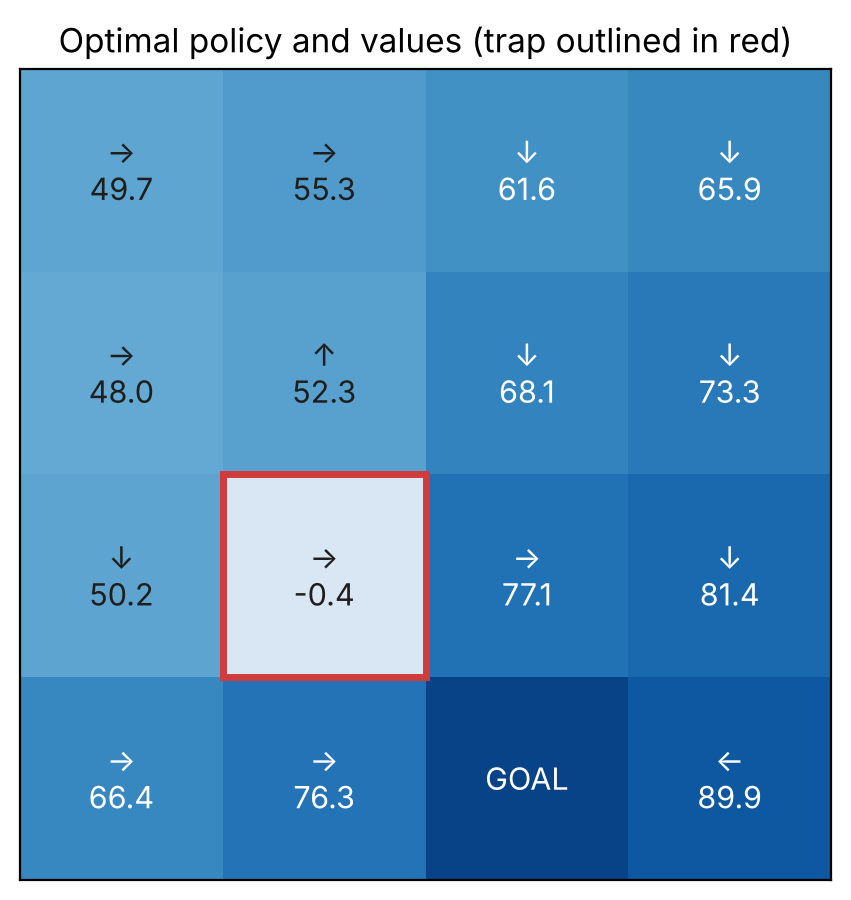

In [4]:
fig, ax = plt.subplots(figsize=(4.6, 4.6))
grid = V_pi[:16].reshape(4, 4)
ax.imshow(grid, cmap="Blues", vmin=-20, vmax=110)
for state in range(16):
    row, col = divmod(state, 4)
    label = "GOAL" if state == 14 else f"{ARROWS[policy_pi[state]]}\n{grid[row, col]:.1f}"
    ax.text(col, row, label, ha="center", va="center", fontsize=11,
            color="white" if grid[row, col] > 60 else "#1f1e1b")
ax.add_patch(plt.Rectangle((0.5, 1.5), 1, 1, fill=False, ec="#d03b3b", lw=2.5))
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Optimal policy and values (trap outlined in red)")
plt.tight_layout()
plt.savefig("figures/maze_optimal_policy.png", dpi=150)
plt.show()

## Modified policy iteration: how many evaluation sweeps?

Modified policy iteration sits between the other two algorithms. With $k = 1$ evaluation sweep it is exactly value iteration, and as $k \to \infty$ the evaluation becomes exact and it turns into policy iteration.

In [5]:
rows = []
for k in range(1, 11):
    policy_k, V_k, it_k, _ = mdp.modified_policy_iteration(n_eval_sweeps=k, tolerance=0.01)
    rows.append({
        "Evaluation sweeps (k)": k,
        "Iterations": it_k,
        "Total backups": it_k * k,
        "Max |V − V*|": np.abs(V_k - V_pi).max().round(3),
        "Optimal policy": np.array_equal(policy_k, policy_pi),
    })
mpi_results = pd.DataFrame(rows).set_index("Evaluation sweeps (k)")
mpi_results

,Iterations,Total backups,Max |V − V*|,Optimal policy
Evaluation sweeps (k),,,,
1,26,26,0.022,True
2,15,30,0.010,True
3,12,36,0.003,True
4,10,40,0.002,True
5,9,45,0.002,True
6,9,54,0.001,True
7,8,56,0.000,True
8,9,72,0.000,True
9,8,72,0.000,True


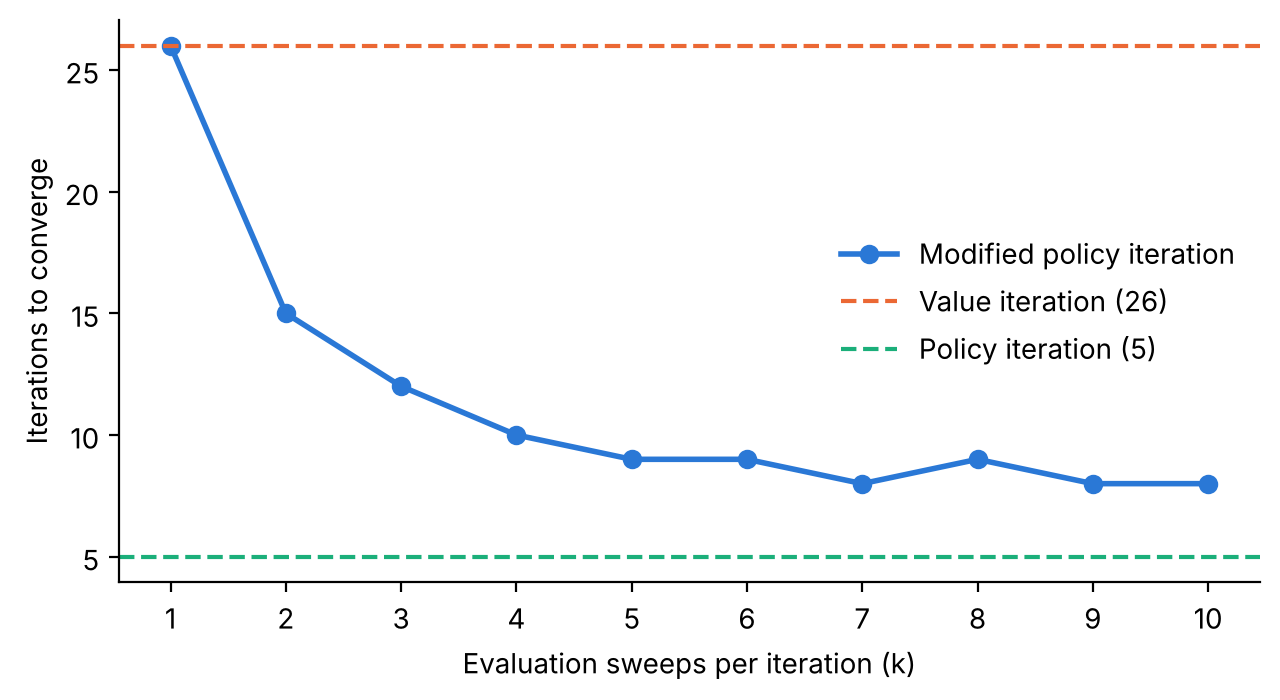

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(mpi_results.index, mpi_results["Iterations"], marker="o", color="#2a78d6", lw=2, label="Modified policy iteration")
ax.axhline(it_vi, color="#eb6834", ls="--", lw=1.5, label=f"Value iteration ({it_vi})")
ax.axhline(it_pi, color="#1baf7a", ls="--", lw=1.5, label=f"Policy iteration ({it_pi})")
ax.set_xlabel("Evaluation sweeps per iteration (k)")
ax.set_ylabel("Iterations to converge")
ax.set_xticks(range(1, 11))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("figures/modified_policy_iteration.png", dpi=150)
plt.show()